# Question 1 – Attribuer des canaux Wi-Fi (6 points)

> **Mode d'emploi du book.**  
> - Exécutez les cellules dans l'ordre (`Maj + Entrée`).
> - Les cellules marquées `# A COMPLETER` sont à compléter ; 
> - les cases ** (R) Réponse** sont à rédiger.
> - zippez ce book avec les autres pour le déposer sur moodle

## Le problème

L'école installe le Wi-Fi dans le bâtiment B : **15 bornes** (points d'accès) réparties sur trois niveaux.  
Deux bornes proches qui émettent **sur le même canal** se brouillent : les débits s'effondrent pour tout le monde.  
Il faut donc attribuer un canal à chaque borne de sorte que **deux bornes en interférence n'utilisent jamais le même canal**.

![Le graphe d'interférences du bâtiment B](images/batimentB.png)

*Figure 1 – Le graphe d'interférences du bâtiment B. Une arête relie deux bornes qui se brouillent si elles partagent un canal.*

Deux bandes de fréquences sont disponibles :

- **2,4 GHz** : seulement **3 canaux** qui ne se recouvrent pas, les canaux 1, 6 et 11 ;
- **5 GHz** : davantage de canaux (36, 40, 44, 48, 52…), mais une portée plus courte et un matériel plus cher.

La question de l'administrateur réseau : *peut-on se contenter de la bande 2,4 GHz ? Sinon, combien de canaux faut-il au minimum ?*

> **Un problème classique : la coloration de graphe.**  
> Les bornes sont les **sommets** d'un graphe, les interférences sont les **arêtes**, les canaux sont des **couleurs**.  
> On cherche à colorier les sommets sans que deux sommets voisins aient la même couleur.  
> Le plus petit nombre de couleurs nécessaires s'appelle le **nombre chromatique** du graphe.  
> C'est le problème de l'exemple `ColorZone` du cours (niveaux de sécurité de zones réseau), à plus grande échelle.

---
## Les données

Le fichier `canaux_wifi.py`, à placer dans le même répertoire que ce jupyter book, contient les données et trois modèles.  
Une instance est un triplet `(nom, bornes, interferences)` : nom de l'instance, la liste des noms des bornes et la liste des paires d'indices des bornes en interférence.

In [1]:
from ortools.sat.python import cp_model
from canaux_wifi import *

nom, bornes, interferences = batiment_b()
print(nom, ":", len(bornes), "bornes,", len(interferences), "interférences")
print("Bornes :", bornes)
print("Les 5 premières interférences :", interferences[:5])

Batiment B : 15 bornes, 28 interférences
Bornes : ['Hall', 'Accueil', 'AmphiA', 'AmphiB', 'Cafet', 'Biblio', 'TP1', 'TP2', 'TP3', 'TP4', 'Bureaux1', 'Direction', 'LaboCyber', 'OpenSpace', 'Reunion']
Les 5 premières interférences : [(0, 1), (0, 2), (0, 3), (0, 4), (0, 5)]


Le fichier contient aussi un générateur d'instances aléatoires, pour tester les modèles sur de plus gros problèmes :

In [2]:
# 60 bornes, densité 15 % (une borne est connectée à 15 % des autres), graine 42 (en fixant la même grain, on obtient toujours la même instance)
instance = instance_aleatoire(60, 0.15, 42)
nom, bornes, interferences = instance
print(nom, ":", len(interferences), "interférences")

Aleatoire n=60 d=0.15 graine=42 : 254 interférences


----
## Partie A – Comprendre le code fourni (3 points)

Les cellules suivantes affichent le code des trois modèles du fichier `canaux_wifi.py`.

### Modèle 1 : une contrainte `!=` par interférence

In [3]:
import inspect
print(inspect.getsource(modele_1))

def modele_1(instance, canaux):
    """modele_1(instance, canaux)
    les bornes de l'instance prennent les valeurs dans un domaine = liste des canaux.  
      *une relation d'interference entre deux bornes est traduite par une contrainte !=.*  
    -param instance = (nom, bornes, relations entre bornes)
    -param canaux = CANAUX_24GHZ(3), CANAUX_5GHZ (8), ou toute liste d'entiers différents.  
    - Return: une affectation des canaux aux bornes de l'instance.
    """
    nom, bornes, interferences = instance
    model = cp_model.CpModel()
    domaine = cp_model.Domain.from_values(canaux)
    canal = [model.new_int_var_from_domain(domaine, f"canal_{b}") for b in bornes]

    for i, j in interferences:
        model.add(canal[i] != canal[j])

    return resoudre(model, canal, instance, "modele 1")



### Modèle 2 : une contrainte `add_all_different` par clique

Une **clique** est un sous graphe dont deux sommets quelconques sont toujours adjacents :   
où chaque borne du groupe est en interférence avec chacune des autres.

- *Exemple :* TP1, TP2, TP3 et TP4 forment une clique de taille 4 (les 6 paires TP1–TP2, TP1–TP3, TP1–TP4,
  TP2–TP3, TP2–TP4 et TP3–TP4 sont des interférences).
  Ces quatre bornes doivent avoir quatre canaux différents : une seule contrainte
  `add_all_different([canal[TP1], canal[TP2], canal[TP3], canal[TP4]])` remplace six contraintes `!=`.
- *Cas limite :* deux bornes en interférence, comme TP3 et Bureaux1, forment une clique de taille 2 ;
  pour elles, `add_all_different` équivaut exactement à `!=`.
- *Contre-exemple :* Hall, Accueil et AmphiB ne forment **pas** une clique : Accueil et AmphiB ne se brouillent pas,
  ils ont le droit d'avoir le même canal.

Le modèle 2 découpe le graphe en cliques (fonction `couverture_par_cliques`) et pose un `add_all_different` par clique.

In [4]:
print(inspect.getdoc(couverture_par_cliques))

couverture_par_cliques(instance)  
Regroupe les aretes, liaisons en cliques maximales (Une **clique** est un sous graphe dont deux sommets quelconques sont toujours adjacents).   
Approche gloutonne donc le nombre de cliques peut ne pas être le plus petit.
- param : instance = (nom, bornes, relations entre bornes)
- Return: liste de cliques (liste de listes des no de bornes inter connectées)


In [5]:
print(inspect.getsource(modele_2))

def modele_2(instance, canaux):
    """modele_2(instance, canaux)
    les bornes de l'instance prennent les valeurs dans un domaine = liste des canaux.  
      *une clique de bornes interconnectées est traduite par une contrainte all_different.*   
    -param instance = (nom, bornes, relations entre bornes)
    -param canaux = CANAUX_24GHZ(3), CANAUX_5GHZ (8), ou toute liste d'entiers différents.  
    - Return: une affectation des canaux aux bornes de l'instance.
    """
    nom, bornes, interferences = instance
    model = cp_model.CpModel()
    domaine = cp_model.Domain.from_values(canaux)
    canal = [model.new_int_var_from_domain(domaine, f"canal_{b}") for b in bornes]

    for clique in couverture_par_cliques(instance):
        model.add_all_different(canal[b] for b in clique)

    return resoudre(model, canal, instance, "modele 2")



---
### Modèle 3 : minimiser le nombre de canaux

In [6]:
print(inspect.getsource(modele_3))

def modele_3(instance):
    """ modele_3(instance)
        Chaque borne recoit un numero de canal entre 0 et n-1.   
          *une relation d'interference entre deux bornes est traduite par une contrainte !=.*  
          *on cherche a minimiser le plus grand numero de canal utilise.*
        - Return: une affectation des canaux aux bornes de l'instance.
    """
    nom, bornes, interferences = instance
    n = len(bornes)
    model = cp_model.CpModel()
    numero = [model.new_int_var(0, n - 1, f"numero_{b}") for b in bornes]
    for i, j in interferences:
        model.add(numero[i] != numero[j])

    plus_grand = model.new_int_var(0, n - 1, "plus_grand_numero")
    model.add_max_equality(plus_grand, numero)
    model.add(numero[0] == 0)                       # cassage de symetrie
    model.minimize(plus_grand)

    solver = nouveau_solveur()
    statut = solver.solve(model)
    afficher_statistiques(model, solver, statut, "modele 3")
    if statut in (cp_model.OPTIMAL, cp_model.FEAS

---
### A.1 Lire les modèles

**(R) Q1.1 –** Complétez le tableau ci-dessous (double-cliquez dessus pour l'éditer).  
Donnez le nombre de contraintes en fonction de *n* (bornes) et *m* (interférences) quand c'est possible,  
puis vérifiez vos formules avec les valeurs affichées par le programme.

| | Modèle 1 | Modèle 2 | Modèle 3 |
|---|---|---|---|
| Que représente une variable ? | | | |
| Quel est son domaine ? | | | |
| Quelles contraintes, combien ? | | | |
| Satisfaction ou optimisation ? | | | |

---
### A.2 Exécuter et interpréter

Chaque modèle affiche une ligne de statistiques : taille du modèle, statut, temps, branchements et conflits.
Voici le modèle 1 avec 4 canaux de la bande 5 GHz :

In [7]:
plan = modele_1(batiment_b(), CANAUX_5GHZ[:4])
print("Plan valide ?", verifier(batiment_b(), plan))

[modele 1] 15 variables, 28 contraintes -> OPTIMAL en 0.078 s (274 branchements, 0 conflits)
  Hall       -> canal 36
  Accueil    -> canal 40
  AmphiA     -> canal 48
  AmphiB     -> canal 44
  Cafet      -> canal 48
  Biblio     -> canal 44
  TP1        -> canal 44
  TP2        -> canal 36
  TP3        -> canal 40
  TP4        -> canal 48
  Bureaux1   -> canal 48
  Direction  -> canal 44
  LaboCyber  -> canal 48
  OpenSpace  -> canal 44
  Reunion    -> canal 48
Plan valide ? True


Et la visualisation de ce plan (les interférences non respectées apparaîtraient en arc rouge) :
*(méthode générée par Claude IA)*

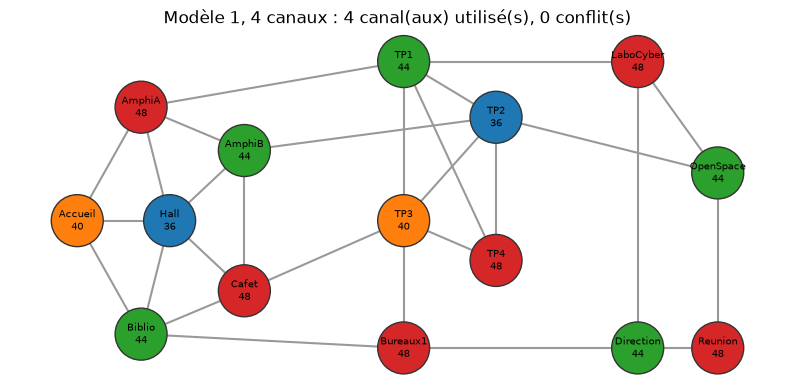

In [8]:
from outils_visu import dessiner_plan
dessiner_plan(plan, "Modèle 1, 4 canaux")

Essayez maintenant avec les 3 canaux de la bande 2,4 GHz, avec les modèles 1 et 2 :

In [9]:
modele_1(batiment_b(), CANAUX_24GHZ)
modele_2(batiment_b(), CANAUX_24GHZ)

[modele 1] 15 variables, 28 contraintes -> INFEASIBLE en 0.004 s (0 branchements, 0 conflits)
  Aucune solution : il n'y a pas assez de canaux.
[modele 2] 15 variables, 18 contraintes -> INFEASIBLE en 0.000 s (0 branchements, 0 conflits)
  Aucune solution : il n'y a pas assez de canaux.


**(R) Q1.2 –** Avec les 3 canaux de la bande 2,4 GHz, il n'y a pas de solution. 
  - Expliquez **pourquoi**, en vous appuyant sur la figure 1.  
  - Le graphe contient-il 4 bornes toutes en interférence deux à deux (une clique de taille 4) ? Où ?  
  - Retirez par la pensée la borne TP4 : il n'y a plus de clique de taille 4. Pourquoi 3 canaux ne suffisent-ils pas quand même ?

<details>
<summary><b>Indice</b></summary>
Un cycle de longueur impaire peut-il être colorié avec 2 couleurs ?

</details>

** Réponse à Q1.2 :**

*(double-cliquez ici pour écrire)*

**(R) Q1.3 –** Avec 3 canaux, les deux modèles répondent `INFEASIBLE` avec **0 branchement** : le solveur a prouvé
l'impossibilité pendant sa phase de simplification (la *présolution*).  
La cellule suivante la désactive le temps d'une expérience.  
- Comparez le nombre de branchements et de conflits des modèles 1 et 2.
- Lequel prouve le plus vite l'impossibilité ? Pourquoi ?

In [10]:
import canaux_wifi

def solveur_sans_presolution(limite=30):
    solver = cp_model.CpSolver()
    solver.parameters.num_workers = 1
    solver.parameters.max_time_in_seconds = limite
    solver.parameters.cp_model_presolve = False      # pas de presolution
    return solver

solveur_normal = canaux_wifi.nouveau_solveur
canaux_wifi.nouveau_solveur = solveur_sans_presolution   # les modeles utilisent ce solveur
modele_1(batiment_b(), CANAUX_24GHZ)
modele_2(batiment_b(), CANAUX_24GHZ)
canaux_wifi.nouveau_solveur = solveur_normal              # on remet le solveur normal

[modele 1] 15 variables, 28 contraintes -> INFEASIBLE en 0.007 s (128 branchements, 15 conflits)
  Aucune solution : il n'y a pas assez de canaux.
[modele 2] 15 variables, 18 contraintes -> INFEASIBLE en 0.004 s (5 branchements, 3 conflits)
  Aucune solution : il n'y a pas assez de canaux.


**(R) Votre réponse à Q1.3 :**

*(double-cliquez ici pour écrire)*

---
### A.3 Comparer sur des instances plus grandes

La cellule suivante lance les modèles 1 et 2 sur deux instances aléatoires, avec un nombre de canaux insuffisant puis juste suffisant.  
Elle peut prendre quelques secondes. 
- Reportez les résultats dans le tableau, 
- puis ajoutez au moins une instance de votre choix (par exemple `instance_aleatoire(120, 0.15, 3)` avec 6 canaux :  
que se passe-t-il au bout de 30 secondes ?).

In [13]:
for (n, densite, graine, nb_canaux) in [(60, 0.15, 42, (4, 5)), (80, 0.2, 1, (5, 6))]:
    inst = instance_aleatoire(n, densite, graine)
    print(f"\n===== {inst[0]} : {len(inst[2])} interferences =====")
    for k in nb_canaux:
        print(f"--- {k} canaux ---")
        modele_1(inst, CANAUX_5GHZ[:k])
        modele_2(inst, CANAUX_5GHZ[:k])


===== Aleatoire n=60 d=0.15 graine=42 : 254 interferences =====
--- 4 canaux ---
[modele 1] 60 variables, 254 contraintes -> INFEASIBLE en 0.057 s (6947 branchements, 773 conflits)
  Aucune solution : il n'y a pas assez de canaux.
[modele 2] 60 variables, 151 contraintes -> INFEASIBLE en 0.026 s (1431 branchements, 113 conflits)
  Aucune solution : il n'y a pas assez de canaux.
--- 5 canaux ---
[modele 1] 60 variables, 254 contraintes -> OPTIMAL en 0.029 s (1080 branchements, 7 conflits)
[modele 2] 60 variables, 151 contraintes -> OPTIMAL en 0.034 s (1622 branchements, 1 conflits)

===== Aleatoire n=80 d=0.2 graine=1 : 624 interferences =====
--- 5 canaux ---
[modele 1] 80 variables, 624 contraintes -> INFEASIBLE en 0.547 s (20178 branchements, 3660 conflits)
  Aucune solution : il n'y a pas assez de canaux.
[modele 2] 80 variables, 308 contraintes -> INFEASIBLE en 0.087 s (2316 branchements, 167 conflits)
  Aucune solution : il n'y a pas assez de canaux.
--- 6 canaux ---
[modele 1] 8

*Aléa 60* désigne `instance_aleatoire(60, 0.15, 42)`, *Aléa 80* désigne `instance_aleatoire(80, 0.2, 1)` ; *k* est le nombre de canaux.

| Instance | k | Modèle | Var. | Contr. | Branch. | Conflits | Temps | Statut |
|---|---|---|---|---|---|---|---|---|
| Bât. B | 3 | 1 | | | | | | |
| Bât. B | 3 | 2 | | | | | | |
| Bât. B | 4 | 1 | | | | | | |
| Bât. B | 4 | 2 | | | | | | |
| Aléa 60 | 4 | 1 | | | | | | |
| Aléa 60 | 4 | 2 | | | | | | |
| Aléa 60 | 5 | 1 | | | | | | |
| Aléa 60 | 5 | 2 | | | | | | |
| Aléa 80 | 5 | 1 | | | | | | |
| Aléa 80 | 5 | 2 | | | | | | |
| Aléa 80 | 6 | 1 | | | | | | |
| Aléa 80 | 6 | 2 | | | | | | |
| … | | | | | | | | |


> **Où le solveur souffre-t-il ?** 
> - Comparez le cas où le nombre de canaux est **juste suffisant** et celui où il en manque **un seul**. 
> - Lorsqu'il n'y a pas de solution, cela oblige le solveur à explorer tout l'arbre de recherche :  
> regarder alors la différence entre modèles.

**(R) Q1.4 – Quel modèle vous semble le plus adéquat, et pourquoi ?** 
- Argumentez selon plusieurs critères :
  - la question posée (existe-t-il un plan à *k* canaux ?  quel est le minimum ?), 
  - la lisibilité, la taille du modèle, la force de la propagation, le comportement mesuré sur les grandes instances.

**Réponse à Q1.4 :**

*(double-cliquez ici pour écrire)*

----

## Partie B – Un modèle booléen (3 points)

Il existe une autre approche : créer **une variable par couple (borne, canal)**.

- `x[b][c]` prend ses valeurs dans {0, 1} : 1 si la borne *b* émet sur le canal *c*, 0 sinon.
- Chaque borne a **exactement un** canal : la somme de chaque ligne de `x` vaut 1.
- Deux bornes *i* et *j* en interférence n'ont pas le même canal : pour chaque canal *c*, `x[i][c] + x[j][c]` est bornée par 1.

> Cela ressemble au  modèle « une variable 0/1 par case de l'échiquier » du problème des *N* reines :   
> somme des lignes égale à 1, somme d'une diagonale bornée par 1.  
> Ici, les « lignes » sont les bornes, les « colonnes » sont les canaux,   
> et les « diagonales » sont les paires (ou les cliques) de bornes en interférence.

| | | Canal 36 | Canal 40 | Canal 44 | Canal 48 | Somme |
|---|---|---|---|---|---|---|
| Borne 0 | Hall | 1 | 0 | 0 | 0 | = 1 |
| Borne 1 | Accueil | 0 | 1 | 0 | 0 | = 1 |
| Borne 2 | AmphiA | 0 | 0 | 1 | 0 | = 1 |
| … | | | | | | |

Hall et Accueil sont en interférence : sur chaque colonne, leurs deux valeurs ont une somme au plus égale à 1.

### B.1 Écrire le modèle

Complétez la fonction suivante. Elle réutilise `nouveau_solveur` et `afficher_statistiques` du code fourni.

In [ ]:
def modele_booleen(instance, canaux):
    # x[b][c] = 1 <=> la borne b emet sur le canal canaux[c].
    # Renvoie le plan (le canal de chaque borne), ou None s'il n'y a pas de solution.
    _, bornes, interferences = instance
    n, k = len(bornes), len(canaux)
    model = cp_model.CpModel()

    # 1. la matrice de variables booleennes : n lignes, k colonnes
    # model.new_bool_var("a") pose la variable booleenne de nom "a" 
    x = ...                                      # A COMPLETER

    # 2. chaque borne a exactement un canal
    # A COMPLETER

    # 3. deux bornes en interference n'ont pas le meme canal
    # A COMPLETER

    # 4. resolution et statistiques
    solver = nouveau_solveur()
    statut = solver.solve(model)
    afficher_statistiques(model, solver, statut, "booleen")
    if statut not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return None

    # 5. reconstruction du plan : pour chaque borne, le canal dont la variable vaut 1
    plan = ...                                   # A COMPLETER
    return plan

<b>Rappel  : les sommes</b>

- `model.add(sum(x[b]) == 1)` pour une ligne.   
- Pour deux variables, `model.add(x[i][c] + x[j][c] <= 1)`.  

OR-Tools propose aussi des raccourcis dédiés aux booléens :   
- `model.add_exactly_one(x[b])` et 
- `model.add_at_most_one(x[i][c], x[j][c])`.   

Testez les deux écritures : le nombre de contraintes change-t-il ?

<details>
<summary><b>Indice 3 : récupérer le plan</b></summary>

`solver.value(x[b][c])` vaut 0 ou 1. Pour chaque borne *b*, cherchez l'indice *c* tel que la valeur vaut 1,
puis prenez `canaux[c]`.

</details>

Testez votre modèle : vous devez retrouver les mêmes conclusions qu'avec les modèles 1 et 2.

In [ ]:
modele_booleen(batiment_b(), CANAUX_24GHZ)               # attendu : INFEASIBLE
plan = modele_booleen(batiment_b(), CANAUX_5GHZ[:4])
print("Plan valide ?", verifier(batiment_b(), plan))
dessiner_plan(plan, "Modèle booléen, 4 canaux")

-----

### B.2 Une variante plus forte

Au lieu d'une contrainte par **paire** de bornes et par canal, posez une contrainte par **clique** et par canal :
- *sur un canal donné, au plus une borne de la clique peut émettre*.   
Réutilisez `couverture_par_cliques(instance)`.

In [ ]:
def modele_booleen_cliques(instance, canaux):
    _, bornes, interferences = instance
    n, k = len(bornes), len(canaux)
    model = cp_model.CpModel()
    # A COMPLETER (s'inspirer de modele_booleen)
    ...

bat_b = batiment_b()
#on tente avec 3 canaux
modele_booleen_cliques(bat_b, CANAUX_24GHZ)
#on tente avec 4 canaux parmis les 8 de CANAUX_5GHZ
plan = modele_booleen_cliques(bat_b, CANAUX_5GHZ[:4])
print("Plan valide ?", verifier(bat_b, plan))

---
### B.3 Comparer

Relancez la comparaison de la partie A.3 en ajoutant vos deux modèles, et ajoutez les lignes correspondantes au tableau.

In [ ]:
for (n, densite, graine, nb_canaux) in [(60, 0.15, 42, (4, 5)), (80, 0.2, 1, (5, 6))]:
    inst = instance_aleatoire(n, densite, graine)
    print(f"\n===== {inst[0]} : {len(inst[2])} interferences =====")
    for k in nb_canaux:
        print(f"--- {k} canaux ---")
        for modele in (modele_1, modele_2, modele_booleen, modele_booleen_cliques):
            modele(inst, CANAUX_5GHZ[:k])

**(R) Q1.5 –** Combien de variables et de contraintes compte le modèle booléen, en fonction de *n*, *m* et *k* ?   
Et sa variante par cliques ?

** Réponse à Q1.5 :**

*(double-cliquez ici pour écrire)*

**(R) Q1.6 –** Le modèle booléen est-il plus rapide ou plus lent que les modèles 1 et 2 ?   
Fait-il plus ou moins de branchements ?  
Distinguez le cas avec solution et le cas sans solution.

<details>
<summary><b>Indice pour l'interprétation</b></summary>

CP-SAT est un solveur **SAT** (logique booléenne) enrichi de propagation de contraintes : en interne, il transforme
lui-même chaque variable entière en un ensemble de variables booléennes. Votre modèle booléen fait donc à la main une
partie de ce que le solveur fait déjà. Cela explique-t-il vos mesures ?

</details>

** Votre réponse à Q1.6 :**

*(double-cliquez ici pour écrire)*

**(R) Q1.7 –** Que se passerait-il si l'on remplaçait « la somme de chaque ligne vaut 1 » par « la somme de chaque
ligne est au moins 1 » ?   
La solution aurait-elle encore un sens pour l'administrateur réseau ?

** Votre réponse à Q1.7 :**

*(double-cliquez ici pour écrire)*